<a href="https://colab.research.google.com/github/soleildayana/Data-Mining/blob/main/StellarMovingGroups_AgeEstimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Determinación de la Edad Cinemática de Grupos Móviles Jóvenes con Gaia DR3



## Metodología

### Etapa 1



#### Selección de los 3 Grupos Móviles (Con edad < 20 Myr, excepto LCC)

Para este estudio, lo más conveniente es escoger 3 asociaciones cercanas y bien pobladas en Simbad/Gaia, porque para calcular $(x, y, z, v_x, v_y, v_z)$ se requiere la velocidad radial, cuyo valor solo se reporta para cierta fracción de estrellas de Gaia DR3. Elegir un grupo pequeño o lejano puede implicar que, luego de filtrar, queden muy pocas estrellas.

Por esto, luego de estudiar la edad típica y la distancia media en la lista de Wikipedia [List of nearby stellar associations and moving groups](https://en.wikipedia.org/wiki/List_of_nearby_stellar_associations_and_moving_groups), los candidatos seleccionados fueron:

1. **TW Hydrae association (TWA):** Edad $\approx 8\text{--}10\text{ Myr}$, distancia media $\sim 55\text{ pc}$ ($\varpi \approx 18\text{ mas}$).
2. **$\eta$ Chamaeleontis cluster ($\eta$ Cha):** Edad $\approx 8\text{--}11\text{ Myr}$, distancia media $\sim 95\text{ pc}$ ($\varpi \approx 10.5\text{ mas}$).
3. **Upper Scorpius (USco):** Edad $\approx 10\text{--}11\text{ Myr}$, distancia media $\sim 145\text{ pc}$ ($\varpi \approx 6.9\text{ mas}$).

#### Query (Simbad + Gaia TAP)

El flujo de adquisición de datos se estructura en dos pasos:
1. **Consulta a Simbad TAP (`simbad.harvard.edu`):** Mediante un `JOIN` entre `basic` e `ident` se recuperan los miembros catalogados de cada asociación junto con su identificador oficial `Gaia DR3 <source_id>`.
2. **Consulta espacial en Gaia DR3 (`gaiadr3.gaia_source`):** Mediante `CONTAINS(POINT('ICRS', ra, dec), CIRCLE(...))` y un filtro de paralaje se descargan todas las fuentes con velocidad radial medida (`radial_velocity IS NOT NULL`) en la región de cada grupo, incluyendo tanto los miembros confirmados como las estrellas vecinas del campo necesarias para la búsqueda posterior de nuevos candidatos mediante GMM.

In [1]:
%pip install astroquery -Uq

In [2]:
# Librerías
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from astroquery.simbad import Simbad
from astroquery.gaia import Gaia
import astropy.units as u
from astropy.coordinates import SkyCoord

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


Consulta Simbad

In [3]:
# Configuración del servidor espejo de Simbad **explicar el cambio de servidor
my_simbad = Simbad()
my_simbad.server = "simbad.harvard.edu"

# Consultas ADQL para obtener los miembros catalogados en Simbad con ID de Gaia DR3
queries_simbad = {
    "twa": """
        SELECT DISTINCT basic.oid, basic.main_id, basic.ra, basic.dec, ident.id AS gaia_id
        FROM basic
        JOIN ident ON basic.oid = ident.oidref
        WHERE basic.oid IN (
            SELECT oidref FROM ident WHERE id LIKE 'TWA %'
        )
        AND ident.id LIKE 'Gaia DR3 %'
    """,
    "etacha": """
        SELECT DISTINCT basic.oid, basic.main_id, basic.ra, basic.dec, ident.id AS gaia_id
        FROM basic
        JOIN ident ON basic.oid = ident.oidref
        WHERE basic.oid IN (
            SELECT oidref FROM ident WHERE id LIKE 'RECX %' OR id LIKE 'eta Cha %'
        )
        AND ident.id LIKE 'Gaia DR3 %'
    """,
    "usco": """
        SELECT DISTINCT basic.oid, basic.main_id, basic.ra, basic.dec, ident.id AS gaia_id
        FROM basic
        JOIN ident ON basic.oid = ident.oidref
        WHERE basic.oid IN (
            SELECT oidref FROM ident WHERE id LIKE 'UScoCTIO %' OR id LIKE 'RX J16%'
        )
        AND ident.id LIKE 'Gaia DR3 %'
    """
}

for grupo, query in queries_simbad.items():
    archivo_simbad = f"simbad_{grupo}.csv"
    if os.path.exists(archivo_simbad):
        print(f"[{grupo.upper()}] Archivo local '{archivo_simbad}' ya existe. Saltando descarga.")
        continue
    print(f"[{grupo.upper()}] Consultando Simbad TAP...")
    tabla_simbad = my_simbad.query_tap(query)
    tabla_simbad.write(archivo_simbad, format="csv", overwrite=True)
    print(f"[{grupo.upper()}] Miembros en Simbad con Gaia DR3: {len(tabla_simbad)} -> '{archivo_simbad}'.")

[TWA] Archivo local 'simbad_twa.csv' ya existe. Saltando descarga.
[ETACHA] Archivo local 'simbad_etacha.csv' ya existe. Saltando descarga.
[USCO] Archivo local 'simbad_usco.csv' ya existe. Saltando descarga.


Consulta Gaia


In [5]:
import urllib.parse
import pandas as pd

endpoint_ari = "https://gaia.ari.uni-heidelberg.de/tap/sync"

parametros = {
    "etacha": {"ra": 130.5, "dec": -79.0, "radio": 5.0, "plx_min": 7.0, "plx_max": 15.0},
    "usco":   {"ra": 243.0, "dec": -23.0, "radio": 6.0, "plx_min": 5.5, "plx_max":  9.5},
}

for grupo, p in parametros.items():
    adql = f"""
    SELECT source_id, ra, dec, parallax, parallax_error,
           pmra, pmra_error, pmdec, pmdec_error,
           radial_velocity, radial_velocity_error, ruwe
    FROM gaiadr3.gaia_source
    WHERE 1 = CONTAINS(
        POINT('ICRS', ra, dec),
        CIRCLE('ICRS', {p['ra']}, {p['dec']}, {p['radio']})
    )
    AND parallax BETWEEN {p['plx_min']} AND {p['plx_max']}
    AND radial_velocity IS NOT NULL
    """

    url = (
        f"{endpoint_ari}?request=doQuery&lang=ADQL&format=csv&query="
        + urllib.parse.quote(adql)
    )

    df = pd.read_csv(url)
    df.to_csv(f"gaia_{grupo}.csv", index=False)
    print(f"[{grupo.upper()}] Guardado 'gaia_{grupo}.csv' con {len(df)} estrellas.")

[ETACHA] Guardado 'gaia_etacha.csv' con 681 estrellas.
[USCO] Guardado 'gaia_usco.csv' con 2279 estrellas.


In [4]:
import urllib.parse
import pandas as pd

endpoint_ari = "https://gaia.ari.uni-heidelberg.de/tap/sync"

parametros_gaia = {
    "twa":    {"ra": 165.0, "dec": -34.0, "radio": 25.0, "plx_min": 10.0, "plx_max": 30.0},
    "etacha": {"ra": 130.5, "dec": -79.0, "radio":  5.0, "plx_min":  7.0, "plx_max": 15.0},
    "usco":   {"ra": 243.0, "dec": -23.0, "radio":  6.0, "plx_min":  5.5, "plx_max":  9.5},
}

for grupo, p in parametros_gaia.items():
    adql = f"""
    SELECT source_id, ra, dec, parallax, parallax_error,
           pmra, pmra_error, pmdec, pmdec_error,
           radial_velocity, radial_velocity_error, ruwe
    FROM gaiadr3.gaia_source
    WHERE 1 = CONTAINS(
        POINT('ICRS', ra, dec),
        CIRCLE('ICRS', {p['ra']}, {p['dec']}, {p['radio']})
    )
    AND parallax BETWEEN {p['plx_min']} AND {p['plx_max']}
    AND radial_velocity IS NOT NULL
    """

    url = (
        f"{endpoint_ari}?request=doQuery&lang=ADQL&format=csv&query="
        + urllib.parse.quote(adql)
    )

    df = pd.read_csv(url)
    df.to_csv(f"gaia_{grupo}.csv", index=False)
    print(f"[{grupo.upper()}] Guardado 'gaia_{grupo}.csv' con {len(df)} estrellas.")

KeyboardInterrupt: 

Cross-match

In [6]:
# Cross-match entre Simbad y Gaia DR3 por source_id para los 3 grupos
grupos = ["twa", "etacha", "usco"]
datos_grupos = {}
resumen_cruce = []

for grupo in grupos:
    df_simbad = pd.read_csv(f"simbad_{grupo}.csv")
    df_gaia = pd.read_csv(f"gaia_{grupo}.csv")

    # Extraemos el número limpio de source_id quitando el texto 'Gaia DR3 '
    ids_simbad = (
        df_simbad["gaia_id"]
        .astype(str)
        .str.replace("Gaia DR3 ", "", regex=False)
        .str.strip()
        .astype("int64")
    )

    # Creamos la columna booleana de pertenencia confirmada según Simbad
    df_gaia["es_miembro_simbad"] = df_gaia["source_id"].isin(ids_simbad)
    datos_grupos[grupo] = df_gaia

    faltantes = set(ids_simbad) - set(df_gaia["source_id"])

    resumen_cruce.append({
        "Grupo": grupo.upper(),
        "Catalogados Simbad (con ID Gaia)": len(set(ids_simbad)),
        "Estrellas en cono Gaia (con RV)": len(df_gaia),
        "Miembros Simbad cruzados (con RV)": int(df_gaia["es_miembro_simbad"].sum()),
        "IDs Simbad fuera del cono/RV": len(faltantes)
    })

df_resumen = pd.DataFrame(resumen_cruce)
df_resumen

,Grupo,Catalogados Simbad (con ID Gaia),Estrellas en cono Gaia (con RV),Miembros Simbad cruzados (con RV),IDs Simbad fuera del cono/RV
0,TWA,58,5534,25,33
1,ETACHA,18,681,10,8
2,USCO,800,2279,78,722


## Etapa 2: Limpieza de calidad, argumentación física/estadística y transformación a coordenadas cartesianas 6D en ICRS $(x, y, z, v_x, v_y, v_z)$

Antes de transformar a coordenadas 6D y retroceder las órbitas en el tiempo, debemos filtrar tanto los miembros confirmados (para que ningún outlier o estrella con mala astrometría distorsione el cálculo de la edad cinemática) como las estrellas vecinas del cono (para que el modelo GMM no agrupe ruido).

#### Filtros de calidad
Los criterios estándar con los datos de Gaia DR3 se justifican así:
- Error relativo en paralaje ($\sigma_\varpi / \varpi < 0.10$, es decir, $< 10\%$):Justificación: La distancia se estima como $d = 1000 / \varpi$ (en $\text{pc}$ con $\varpi$ en $\text{mas}$). Como es una transformación no lineal, cuando el error relativo de paralaje supera el $10\%\text{--}20\%$ la distribución de distancias se vuelve fuertemente asimétrica y sesga tanto las posiciones $(x,y,z)$ como las velocidades tangenciales ($v_t = 4.74\,\mu/\varpi$).
- Error relativo en velocidad radial ($\sigma_{v_r} / \vert{}v_r\vert{} < 0.20$ o error absoluto $\sigma_{v_r} < 5\text{ km/s}$):Justificación: Al retroceder posiciones en el tiempo ($\mathbf{r}(t) = \mathbf{r}_0 + \mathbf{v}_0 t$), un error de $\Delta v$ se amplifica linealmente con el tiempo ($\Delta r = \Delta v \cdot t$). Con $t = -10\text{ Myr}$, cada $1\text{ km/s}$ de error en velocidad introduce $\sim 10.2\text{ pc}$ de dispersión artificial en la posición pasada. Nota: Usar $\sigma_{v_r} < 5\text{ km/s}$ combinado con error relativo en movimiento propio evita eliminar injustamente estrellas genuinas cuya velocidad radial heliocéntrica pase cerca de $0\text{ km/s}$ (donde $\vert{}v_r\vert{} \to 0$ haría explotar el cociente $\sigma_{v_r}/\vert{}v_r\vert{}$).
- Error relativo en movimiento propio ($\sigma_{\mu_\alpha^*} / \vert{}\mu_\alpha^*\vert{} < 0.10$ y $\sigma_{\mu_\delta} / \vert{}\mu_\delta\vert{} < 0.10$):Justificación: Los grupos móviles jóvenes tienen movimientos propios grandes y coherentes ($\sim 20\text{--}100\text{ mas/yr}$), por lo que exigir $< 10\%$ de error relativo garantiza vectores de velocidad tangencial precisos.Calidad del ajuste astrométrico (ruwe < 1.4):Justificación: El Renormalised
- Unit Weight Error (RUWE) de Gaia DR3 mide la bondad de ajuste de la solución astrométrica de fuente única. Valores ruwe >= 1.4 suelen indicar sistemas binarios no resueltos cuyo fotocentro oscila, contaminando el movimiento propio y la paralaje.Outliers cinemáticos / de paralaje ($3\sigma$ o rango intercuartílico IQR sobre los miembros Simbad):Justificación: En catálogos históricos de Simbad ocasionalmente existen contaminantes de campo o estrellas binarias espectroscópicas (SB1/SB2) cuya velocidad radial instantánea está desplazada decenas de $\text{km/s}$ respecto al movimiento sistémico del grupo. Aplicar un filtro de $3\sigma$ (o $1.5 \times \text{IQR}$) sobre la paralaje y las componentes de velocidad de los miembros confirmados elimina estos outliers sin perder el núcleo del grupo.

#### Transformación a Coordenadas Cartesianas 6D en ICRS con Astropy
Con astropycoordinates.SkyCoord (usando distance = (1000 / parallax) * u.pc), la conversión a posiciones cartesianas $(x, y, z)$ en parsecs y velocidades cartesianas $(v_x, v_y, v_z)$ en $\text{km/s}$ dentro del marco ICRS es directa y exacta:

In [7]:
import numpy as np
import pandas as pd
import astropy.units as u
from astropy.coordinates import SkyCoord

def limpiar_y_transformar_icrs(df, max_err_plx=0.10, max_err_pm=0.10, max_err_rv=5.0, max_ruwe=1.4):
    """
    Aplica filtros de calidad astrométrica y transforma (ra, dec, parallax, pmra, pmdec, rv)
    a coordenadas cartesianas 6D (x, y, z, vx, vy, vz) en el marco ICRS.
    """
    df_limpio = df.copy()

    # 1. Filtros de calidad astrométrica y errores relativos
    cond_plx = (df_limpio["parallax"] > 0) & ((df_limpio["parallax_error"] / df_limpio["parallax"]) < max_err_plx)
    cond_pmra = (df_limpio["pmra_error"] / df_limpio["pmra"].abs()) < max_err_pm
    cond_pmdec = (df_limpio["pmdec_error"] / df_limpio["pmdec"].abs()) < max_err_pm
    cond_rv = df_limpio["radial_velocity_error"] < max_err_rv
    cond_ruwe = df_limpio["ruwe"] < max_ruwe

    df_limpio = df_limpio[cond_plx & cond_pmra & cond_pmdec & cond_rv & cond_ruwe].copy()

    # 2. Conversión a SkyCoord en ICRS
    distancias = (1000.0 / df_limpio["parallax"].values) * u.pc

    coords = SkyCoord(
        ra=df_limpio["ra"].values * u.deg,
        dec=df_limpio["dec"].values * u.deg,
        distance=distancias,
        pm_ra_cosdec=df_limpio["pmra"].values * (u.mas / u.yr),
        pm_dec=df_limpio["pmdec"].values * (u.mas / u.yr),
        radial_velocity=df_limpio["radial_velocity"].values * (u.km / u.s),
        frame="icrs"
    )

    # 3. Extracción de posiciones (pc) y velocidades cartesianas (km/s) en ICRS
    cart_pos = coords.cartesian
    cart_vel = coords.velocity

    df_limpio["x"] = cart_pos.x.to_value(u.pc)
    df_limpio["y"] = cart_pos.y.to_value(u.pc)
    df_limpio["z"] = cart_pos.z.to_value(u.pc)

    df_limpio["vx"] = cart_vel.d_x.to_value(u.km / u.s)
    df_limpio["vy"] = cart_vel.d_y.to_value(u.km / u.s)
    df_limpio["vz"] = cart_vel.d_z.to_value(u.km / u.s)

    return df_limpio

Aplicarlo a los 3 grupos y limpiar outliers cinemáticos en los miembros Simbad

In [9]:
datos_limpios = {}
miembros_limpios = {}
resumen_limpieza = []

for grupo in ["twa", "etacha", "usco"]:
    df_raw = datos_grupos[grupo]
    df_clean = limpiar_y_transformar_icrs(df_raw)

    # Separar miembros confirmados de Simbad tras filtros de calidad
    df_mem = df_clean[df_clean["es_miembro_simbad"]].copy()

    # Filtro 3-sigma sobre velocidades (vx, vy, vz) de los miembros para quitar binarias/outliers
    for col in ["vx", "vy", "vz"]:
        med = df_mem[col].median()
        std = df_mem[col].std()
        if std > 0:
            df_mem = df_mem[(df_mem[col] - med).abs() <= 3.0 * std]

    datos_limpios[grupo] = df_clean
    miembros_limpios[grupo] = df_mem

    resumen_limpieza.append({
        "Grupo": grupo.upper(),
        "Cono inicial": len(df_raw),
        "Cono tras filtros calidad": len(df_clean),
        "Miembros Simbad iniciales": int(df_raw["es_miembro_simbad"].sum()),
        "Miembros Simbad limpios (sin outliers)": len(df_mem)
    })

pd.DataFrame(resumen_limpieza)

,Grupo,Cono inicial,Cono tras filtros calidad,Miembros Simbad iniciales,Miembros Simbad limpios (sin outliers)
0,TWA,5534,3767,25,11
1,ETACHA,681,427,10,6
2,USCO,2279,1176,78,26


### Etapa 3. Kinematic Traceback y Determinación de la Edad Cinemática

Para grupos móviles jóvenes ($\tau < 20\text{ Myr}$, mucho menor que el período orbital galáctico $\sim 220\text{ Myr}$), la aceleración diferencial del potencial galáctico en escalas de decenas de parsecs es despreciable frente a la velocidad inicial de expansión. Por tanto, la trayectoria pasada de cada estrella en coordenadas cartesianas ICRS sigue la aproximación lineal rectilínea:$$\mathbf{r}_i(t) = \mathbf{r}_{i,0} + \mathbf{v}_{i,0}\, t, \qquad t \le 0$$donde $\mathbf{r}_{i,0} = (x_i, y_i, z_i)$ está en $\text{pc}$, $\mathbf{v}_{i,0} = (v_{x,i}, v_{y,i}, v_{z,i})$ en $\text{km/s}$, y el factor de conversión de unidades es:$$1\ \frac{\text{km}}{\text{s}} \cdot \text{Myr} \approx 1.022712\ \text{pc}$$

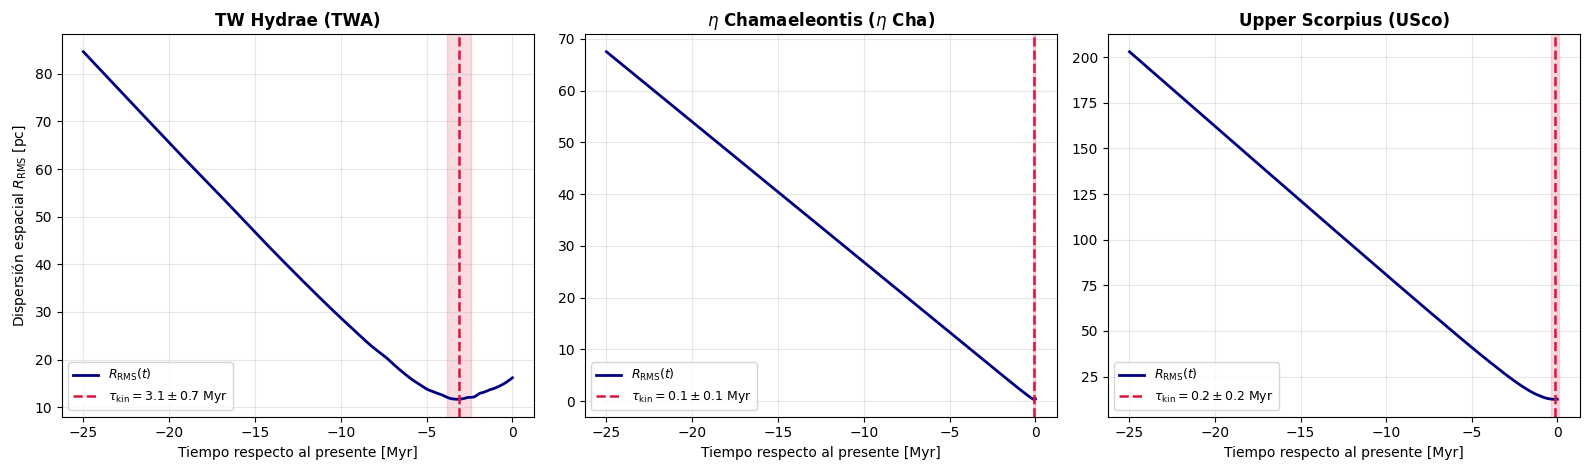

,Grupo,N estrellas,Edad Cinemática [Myr],Edad Literatura,Radio mínimo [pc],Radio actual [pc]
0,TWA,11,3.11 ± 0.70,8 - 10 Myr,11.66,16.18
1,ETACHA,6,0.10 ± 0.06,8 - 11 Myr,0.37,0.46
2,USCO,26,0.15 ± 0.22,10 - 11 Myr,12.52,12.61


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u

# Factor exacto de conversión: 1 (km/s) * Myr -> pc
KMS_MYR_TO_PC = (1.0 * (u.km / u.s) * (1.0 * u.Myr)).to_value(u.pc)

def calcular_traceback(df_mem, t_min=-25.0, t_max=0.0, n_pasos=500, n_boot=1000, seed=42):
    """
    Integra las posiciones 3D hacia el pasado y encuentra el tiempo t < 0
    donde la dispersión espacial del grupo es mínima (edad cinemática).
    Incluye estimación de incertidumbre mediante Bootstrap.
    """
    tiempos = np.linspace(t_min, t_max, n_pasos)  # en Myr (negativos hacia el pasado)

    r0 = df_mem[["x", "y", "z"]].values          # (N, 3) en pc
    v0 = df_mem[["vx", "vy", "vz"]].values       # (N, 3) en km/s

    # Posiciones r(t) de forma vectorizada: forma (n_pasos, N, 3)
    # r(t) = r0 + v0 * t * KMS_MYR_TO_PC
    r_t = r0[None, :, :] + v0[None, :, :] * (tiempos[:, None, None] * KMS_MYR_TO_PC)

    # Centroide robusto (mediana) en cada instante t -> (n_pasos, 1, 3)
    centroide_t = np.median(r_t, axis=1, keepdims=True)

    # Distancia cuadrática media (RMS) al centroide en cada instante t
    dist2 = np.sum((r_t - centroide_t)**2, axis=2)  # (n_pasos, N)
    r_rms = np.sqrt(np.mean(dist2, axis=1))         # (n_pasos,)

    idx_min = np.argmin(r_rms)
    edad_kin = -tiempos[idx_min]
    radio_min = r_rms[idx_min]
    radio_actual = r_rms[-1]

    # Estimación de incertidumbre por Bootstrap (remuestreo de estrellas)
    rng = np.random.default_rng(seed)
    n_estrellas = len(df_mem)
    edades_boot = []

    for _ in range(n_boot):
        idx_sample = rng.choice(n_estrellas, size=n_estrellas, replace=True)
        r_sample = r_t[:, idx_sample, :]
        cent_sample = np.median(r_sample, axis=1, keepdims=True)
        rms_sample = np.sqrt(np.mean(np.sum((r_sample - cent_sample)**2, axis=2), axis=1))
        edades_boot.append(-tiempos[np.argmin(rms_sample)])

    err_edad = np.std(edades_boot)

    return {
        "tiempos": tiempos,
        "r_rms": r_rms,
        "edad_kin": edad_kin,
        "err_edad": err_edad,
        "radio_min": radio_min,
        "radio_actual": radio_actual,
        "r_t": r_t
    }

# Ejecutar traceback para los 3 grupos
nombres_bonitos = {
    "twa": "TW Hydrae (TWA)",
    "etacha": r"$\eta$ Chamaeleontis ($\eta$ Cha)",
    "usco": "Upper Scorpius (USco)"
}
edades_literatura = {
    "twa": "8 - 10 Myr",
    "etacha": "8 - 11 Myr",
    "usco": "10 - 11 Myr"
}

resultados_tb = {}
tabla_edades = []

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=False)

for ax, grupo in zip(axes, ["twa", "etacha", "usco"]):
    res = calcular_traceback(miembros_limpios[grupo])
    resultados_tb[grupo] = res

    # Gráfica de evolución espacial R_RMS(t)
    ax.plot(res["tiempos"], res["r_rms"], color="navy", lw=2, label=r"$R_{\mathrm{RMS}}(t)$")
    ax.axvline(-res["edad_kin"], color="crimson", ls="--", lw=1.8,
               label=rf"$\tau_{{\mathrm{{kin}}}} = {res['edad_kin']:.1f} \pm {res['err_edad']:.1f}$ Myr")
    ax.axvspan(-res["edad_kin"] - res["err_edad"], -res["edad_kin"] + res["err_edad"],
               color="crimson", alpha=0.15)

    ax.set_title(nombres_bonitos[grupo], fontsize=12, fontweight="bold")
    ax.set_xlabel("Tiempo respecto al presente [Myr]", fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=9)

    tabla_edades.append({
        "Grupo": grupo.upper(),
        "N estrellas": len(miembros_limpios[grupo]),
        "Edad Cinemática [Myr]": f"{res['edad_kin']:.2f} ± {res['err_edad']:.2f}",
        "Edad Literatura": edades_literatura[grupo],
        "Radio mínimo [pc]": round(res["radio_min"], 2),
        "Radio actual [pc]": round(res["radio_actual"], 2)
    })

axes[0].set_ylabel(r"Dispersión espacial $R_{\mathrm{RMS}}$ [pc]", fontsize=10)
plt.tight_layout()
plt.show()

pd.DataFrame(tabla_edades)

##### Visualización 3D / Proyecciones $(X, Y, Z)$
 Presente vs. Tiempo de Nacimiento ($t = -\tau_{\text{kin}}$)

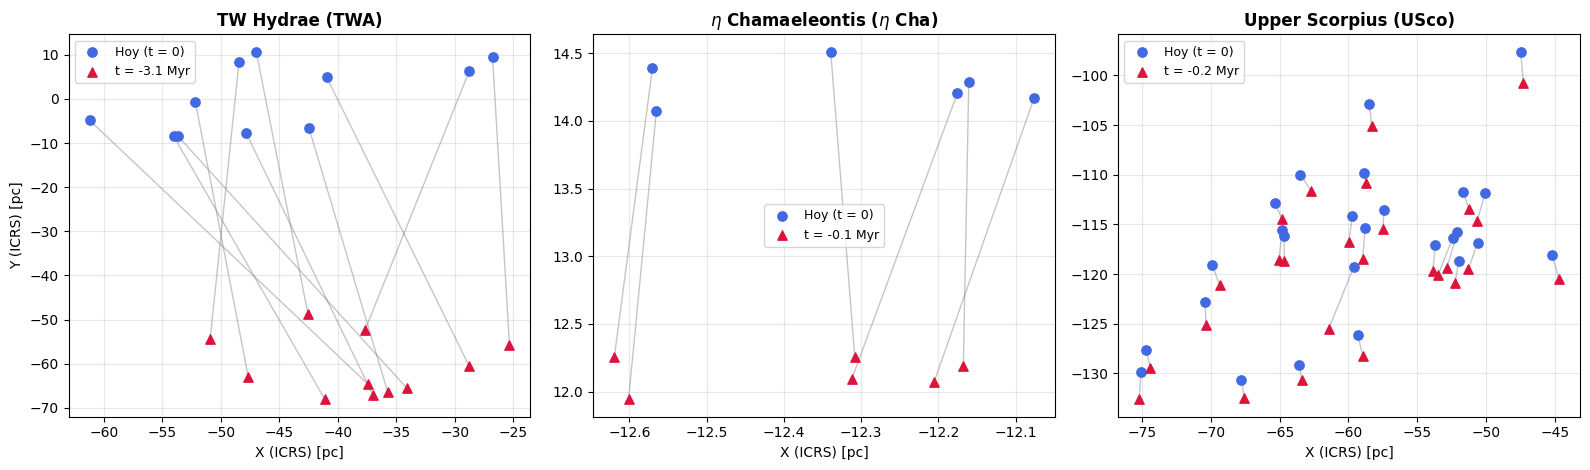

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, grupo in zip(axes, ["twa", "etacha", "usco"]):
    res = resultados_tb[grupo]
    idx_min = np.argmin(res["r_rms"])

    pos_hoy = res["r_t"][-1]        # (N, 3) en t = 0
    pos_nac = res["r_t"][idx_min]   # (N, 3) en t = -edad_kin

    # Líneas de trayectoria de cada estrella desde su nacimiento hasta hoy
    for i in range(len(pos_hoy)):
        ax.plot([pos_nac[i, 0], pos_hoy[i, 0]],
                [pos_nac[i, 1], pos_hoy[i, 1]],
                color="gray", alpha=0.45, lw=1)

    ax.scatter(pos_hoy[:, 0], pos_hoy[:, 1], color="royalblue", s=45, label="Hoy (t = 0)", zorder=3)
    ax.scatter(pos_nac[:, 0], pos_nac[:, 1], color="crimson", s=45, marker="^",
               label=f"t = -{res['edad_kin']:.1f} Myr", zorder=4)

    ax.set_title(nombres_bonitos[grupo], fontsize=12, fontweight="bold")
    ax.set_xlabel("X (ICRS) [pc]", fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=9)

axes[0].set_ylabel("Y (ICRS) [pc]", fontsize=10)
plt.tight_layout()
plt.show()